# Older vs. newer movies

**Question:** are older movies better than newer ones, once we compare them on fair terms?

Two parts:

1. **Compare the eras at the same level.** Line up the eras at each percentile of rating, and at
   each level of popularity within the era, instead of comparing one average to another.
2. **What makes a movie good in each era?** Fit the same regression for every era and compare what
   drives ratings, then check whether knowing the era improves predictions.

**Data:** IMDb movies with at least 1,000 votes, released 1920-2025, joined to Oscar nominations by
IMDb ID. "Better" here means a higher IMDb rating.

**Eras:** Old (before 1980), Middle (1980-1999), New (2000 and later).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor

processed_data_directory = Path("../data/processed")

MIN_VOTES = 1_000
ERAS = ["Old", "Middle", "New"]
ERA_LABELS = {"Old": "Old (before 1980)", "Middle": "Middle (1980-1999)", "New": "New (2000+)"}
# Eras are ordered, so one hue from dark (oldest) to light (newest)
ERA_COLORS = {"Old": "#0b3d78", "Middle": "#2a78d6", "New": "#86b6ec"}

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": "#52514e",
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e8e7e2",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

## Load the data

The cleaned IMDb file already has ratings joined on. From the Oscars we only need how many
nominations each film received. Technical and honorary awards are left out, and a nomination that
lists several films counts for each of them.

In [2]:
imdb = pd.read_csv(processed_data_directory / "imdb_cleaned.csv")
oscars = pd.read_csv(processed_data_directory / "oscars_cleaned.csv")

film_nominations = oscars[~oscars["Class"].isin(["SciTech", "Special"])].dropna(subset=["FilmId"])
oscar_nominations = (
    film_nominations.assign(FilmId=film_nominations["FilmId"].str.split("|"))
    .explode("FilmId")
    .groupby("FilmId")
    .size()
)

print(f"IMDb movies: {len(imdb):,}")
print(f"Films with at least one Oscar nomination: {len(oscar_nominations):,}")

IMDb movies: 708,304
Films with at least one Oscar nomination: 5,250


## Build the analysis table

- **At least 1,000 votes**, so each rating reflects a reasonable number of people.
- **1920-2025.** Few earlier movies have enough votes, and 2026 movies are still collecting them.
- **Popularity within the era.** IMDb has far more users now than it once did, so a raw vote count
  means something different for a 1950s movie than for a 2015 one. `popularity_pct` ranks each
  movie's votes against movies from its own era (0 = least voted, 1 = most voted).
- **Runtime** is in hours and capped at 4, since a handful of listings run for many hours.
- **Genres:** IMDb lists up to three per movie, so each genre is its own 0/1 column. The 12 most
  common genres are kept.

In [3]:
movies = imdb[
    (imdb["numVotes"] >= MIN_VOTES) & imdb["startYear"].between(1920, 2025)
].dropna(subset=["genres", "runtimeMinutes"]).copy()

movies["era"] = pd.cut(movies["startYear"], bins=[0, 1979, 1999, 3000], labels=ERAS)
movies["popularity_pct"] = movies.groupby("era", observed=True)["numVotes"].rank(pct=True)
movies["runtime_hours"] = movies["runtimeMinutes"].clip(upper=240) / 60
movies["oscar_nominated"] = movies["tconst"].isin(oscar_nominations.index).astype(int)

top_genres = movies["genres"].str.split(",").explode().value_counts().head(12).index
GENRE_COLUMNS = []
for genre in top_genres:
    column = genre.replace("-", "")
    movies[column] = movies["genres"].str.split(",").apply(lambda genres: genre in genres).astype(int)
    GENRE_COLUMNS.append(column)

movies.groupby("era", observed=True).agg(
    movies=("tconst", "size"),
    median_rating=("averageRating", "median"),
    median_votes=("numVotes", "median"),
    oscar_nominated=("oscar_nominated", "mean"),
).round(3)

,movies,median_rating,median_votes,oscar_nominated
era,,,,
Old,8517,6.7,2647.0,0.183
Middle,7727,6.4,4318.0,0.089
New,32222,6.3,3395.5,0.032


# Part 1: Compare the eras at the same level

### At each percentile of rating

Instead of one average per era, this lines up the worst-rated 10% of each era, the median, the best
10%, and so on.

In [4]:
PERCENTILES = [0.10, 0.25, 0.50, 0.75, 0.90, 0.99]

rating_percentiles = (
    movies.groupby("era", observed=True)["averageRating"]
    .quantile(PERCENTILES)
    .unstack()
    .rename(columns=lambda p: f"{p:.0%}")
)
rating_percentiles

,10%,25%,50%,75%,90%,99%
era,,,,,,
Old,5.5,6.2,6.7,7.2,7.7,8.3
Middle,4.8,5.6,6.4,7.1,7.6,8.5
New,4.5,5.4,6.3,7.0,7.5,8.3


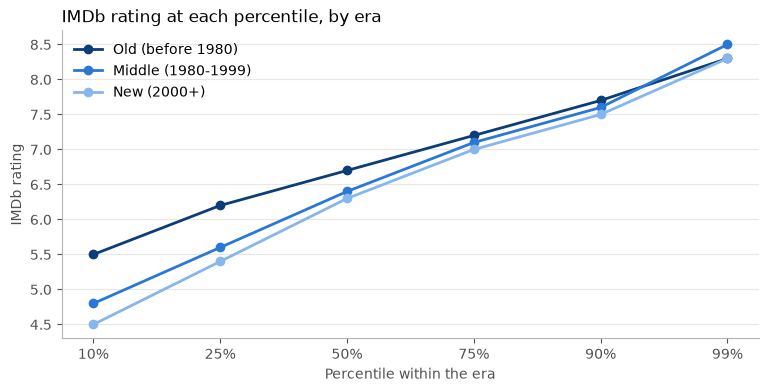

In [5]:
fig, ax = plt.subplots()
for era in ERAS:
    values = rating_percentiles.loc[era]
    ax.plot(values.index, values.values, color=ERA_COLORS[era], linewidth=2, marker="o",
            markersize=6, label=ERA_LABELS[era])
ax.set_title("IMDb rating at each percentile, by era")
ax.set_xlabel("Percentile within the era")
ax.set_ylabel("IMDb rating")
ax.legend(frameon=False)
plt.show()

### At each level of popularity within the era

Old movies that still get rated are mostly the remembered ones. Comparing movies at the same
popularity rank within their own era (for example, each era's top 10% most-voted) puts the eras on
more equal footing.

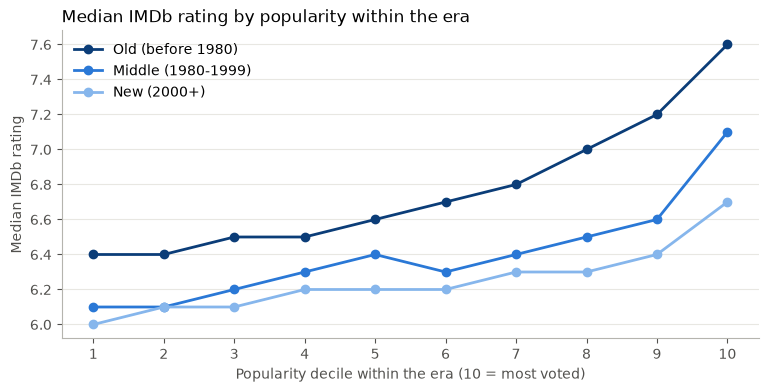

era,Old,Middle,New
popularity_decile,,,
1,6.4,6.1,6.0
2,6.4,6.1,6.1
3,6.5,6.2,6.1
4,6.5,6.3,6.2
5,6.6,6.4,6.2
6,6.7,6.3,6.2
7,6.8,6.4,6.3
8,7.0,6.5,6.3
9,7.2,6.6,6.4


In [6]:
movies["popularity_decile"] = np.ceil(movies["popularity_pct"] * 10).astype(int)

rating_by_popularity = (
    movies.groupby(["popularity_decile", "era"], observed=True)["averageRating"]
    .median()
    .unstack()
)

fig, ax = plt.subplots()
for era in ERAS:
    ax.plot(rating_by_popularity.index, rating_by_popularity[era], color=ERA_COLORS[era],
            linewidth=2, marker="o", markersize=6, label=ERA_LABELS[era])
ax.set_title("Median IMDb rating by popularity within the era")
ax.set_xlabel("Popularity decile within the era (10 = most voted)")
ax.set_ylabel("Median IMDb rating")
ax.set_xticks(range(1, 11))
ax.legend(frameon=False)
plt.show()

rating_by_popularity.round(2)

### Are the differences real?

One-way ANOVA tests whether the era means differ, and Tukey's HSD compares each pair of eras. With
tens of thousands of movies almost any difference will be significant, so the size of the
difference (`meandiff`, in rating points) matters more than the p-value. The test is run on all
movies and again on each era's 10% most-voted.

In [7]:
def compare_eras(data, label):
    model = smf.ols("averageRating ~ C(era)", data=data).fit()
    print(f"--- {label}: {len(data):,} movies ---")
    print(sm.stats.anova_lm(model))
    print(pairwise_tukeyhsd(data["averageRating"], data["era"].astype(str)))


compare_eras(movies, "All movies")
compare_eras(movies[movies["popularity_decile"] == 10], "Each era's 10% most-voted")

--- All movies: 48,466 movies ---
               df        sum_sq     mean_sq           F         PR(>F)
C(era)        2.0   1902.813829  951.406915  729.501266  7.194618e-313
Residual  48463.0  63204.870875    1.304188         NaN            NaN


Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
Middle    New  -0.2013   0.0 -0.2352 -0.1674   True
Middle    Old   0.3225   0.0  0.2804  0.3645   True
   New    Old   0.5238   0.0  0.4912  0.5564   True
---------------------------------------------------
--- Each era's 10% most-voted: 4,848 movies ---
              df       sum_sq     mean_sq           F         PR(>F)
C(era)       2.0   421.129264  210.564632  303.629315  5.857858e-125
Residual  4845.0  3359.970833    0.693492         NaN            NaN
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower  upper  reject
--------------------------------------------------
Middle    New  -0.3432   0.0 -0.4214 -0.265   True
Middle    Old   0.4268   0.0  0.3299 0.5238   True
   New    Old     0.77   0.0  0.6948 0.8452   True
--------------------------------------------------


# Part 2: What makes a movie good in each era?

The same features describe every movie: popularity within its era, runtime, whether it was
nominated for an Oscar, and its genres. The models below ask:

1. Does knowing a movie's era improve predictions of its rating?
2. Do the features matter differently in different eras? This uses era x feature interactions.

### Multicollinearity check

In [8]:
FEATURES = ["popularity_pct", "runtime_hours", "oscar_nominated", *GENRE_COLUMNS]

feature_matrix = sm.add_constant(movies[FEATURES])
pd.Series(
    [variance_inflation_factor(feature_matrix.values, i) for i in range(1, feature_matrix.shape[1])],
    index=FEATURES,
    name="VIF",
).round(2).sort_values(ascending=False)

Drama              1.62
Comedy             1.50
Horror             1.40
Documentary        1.38
Action             1.30
Thriller           1.26
Adventure          1.24
Romance            1.17
popularity_pct     1.15
runtime_hours      1.15
Crime              1.14
Mystery            1.13
oscar_nominated    1.11
Biography          1.11
Fantasy            1.05
Name: VIF, dtype: float64

### Compare models with 5-fold cross-validation

20% of movies are held out for a final test, stratified so each era keeps its share. Model choice
uses 5-fold cross-validation on the other 80%.

| Model | Inputs |
|---|---|
| Baseline | Predicts the average rating for every movie |
| No era | The features only |
| Era | The features plus the era |
| Era x features | The features, the era, and every era x feature interaction |

Each model with features is fit with OLS, ridge, and lasso. The features are standardized first, so
the penalty treats them equally.

In [9]:
train, test = train_test_split(movies, test_size=0.2, random_state=42, stratify=movies["era"])
cv_folds = KFold(n_splits=5, shuffle=True, random_state=42)

feature_terms = " + ".join(FEATURES)
FORMULAS = {
    "No era": f"averageRating ~ {feature_terms}",
    "Era": f"averageRating ~ C(era, Treatment('New')) + {feature_terms}",
    "Era x features": f"averageRating ~ C(era, Treatment('New')) * ({feature_terms})",
}
ESTIMATORS = {
    "OLS": LinearRegression(),
    "Ridge": RidgeCV(alphas=np.logspace(-3, 3, 25)),
    "Lasso": LassoCV(cv=5, random_state=42),
}


def design(formula, data):
    """Outcome and design matrix from a formula, without the intercept column (sklearn adds one)."""
    y, X = dmatrices(formula, data, return_type="dataframe")
    return y["averageRating"], X.drop(columns="Intercept")


def cv_rmse(estimator, X, y):
    scores = cross_validate(estimator, X, y, cv=cv_folds, scoring="neg_root_mean_squared_error")
    return -scores["test_score"].mean()


y_train = train["averageRating"]
results = [{"Model": "Baseline", "Estimator": "Mean",
            "Features": 0, "CV RMSE": cv_rmse(DummyRegressor(), train[FEATURES], y_train)}]
for model_name, formula in FORMULAS.items():
    y, X = design(formula, train)
    for estimator_name, estimator in ESTIMATORS.items():
        results.append({
            "Model": model_name,
            "Estimator": estimator_name,
            "Features": X.shape[1],
            "CV RMSE": cv_rmse(make_pipeline(StandardScaler(), estimator), X, y),
        })

cv_results = pd.DataFrame(results)
cv_results["CV RMSE"] = cv_results["CV RMSE"].round(4)
cv_results

,Model,Estimator,Features,CV RMSE
0,Baseline,Mean,0,1.1598
1,No era,OLS,15,0.9611
2,No era,Ridge,15,0.9611
3,No era,Lasso,15,0.9611
4,Era,OLS,17,0.9387
5,Era,Ridge,17,0.9387
6,Era,Lasso,17,0.9387
7,Era x features,OLS,47,0.9328
8,Era x features,Ridge,47,0.9328
9,Era x features,Lasso,47,0.9328


The era coefficients from the "Era" model are the rating gap to new movies, holding popularity
within the era, runtime, Oscar nomination, and genre constant.

In [10]:
era_fit = smf.ols(FORMULAS["Era"], data=train).fit()
era_terms = [term for term in era_fit.params.index if term.startswith("C(era")]
pd.DataFrame({
    "Rating gap vs. new movies": era_fit.params[era_terms],
    "95% CI low": era_fit.conf_int().loc[era_terms, 0],
    "95% CI high": era_fit.conf_int().loc[era_terms, 1],
}).round(3)

,Rating gap vs. new movies,95% CI low,95% CI high
"C(era, Treatment('New'))[T.Old]",0.565,0.538,0.592
"C(era, Treatment('New'))[T.Middle]",0.282,0.256,0.309


### How each feature's effect differs by era

The same OLS model, fit separately for each era on the training set. Each dot is the change in
rating for one feature, with its 95% confidence interval. This is equivalent to the era x features
model, but easier to read.

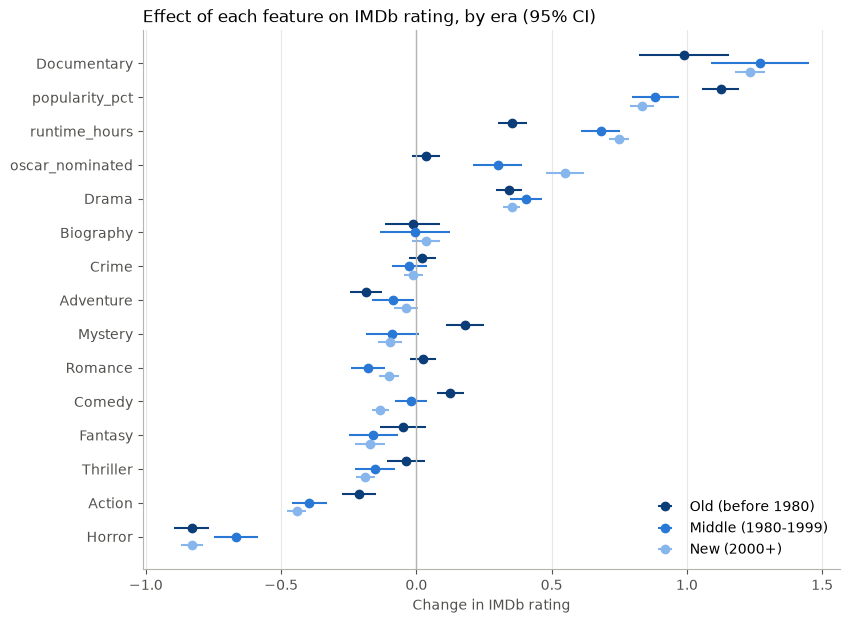

era,Old,Middle,New
feature,,,
Documentary,0.99,1.27,1.23
popularity_pct,1.12,0.88,0.83
runtime_hours,0.36,0.68,0.75
oscar_nominated,0.03,0.30,0.55
Drama,0.34,0.41,0.35
Biography,-0.01,-0.01,0.04
Crime,0.02,-0.03,-0.01
Adventure,-0.19,-0.09,-0.04
Mystery,0.18,-0.09,-0.10


In [11]:
era_coefficients = []
for era in ERAS:
    fit = smf.ols(f"averageRating ~ {feature_terms}", data=train[train["era"] == era]).fit()
    interval = fit.conf_int()
    for feature in FEATURES:
        era_coefficients.append({
            "era": era,
            "feature": feature,
            "coefficient": fit.params[feature],
            "low": interval.loc[feature, 0],
            "high": interval.loc[feature, 1],
        })
era_coefficients = pd.DataFrame(era_coefficients)

# Sort features by their effect in new movies
feature_order = (
    era_coefficients[era_coefficients["era"] == "New"]
    .sort_values("coefficient")["feature"].tolist()
)
positions = {feature: i for i, feature in enumerate(feature_order)}
offsets = {"Old": 0.25, "Middle": 0, "New": -0.25}

fig, ax = plt.subplots(figsize=(9, 7))
for era in ERAS:
    rows = era_coefficients[era_coefficients["era"] == era]
    y_positions = rows["feature"].map(positions) + offsets[era]
    ax.errorbar(rows["coefficient"], y_positions,
                xerr=[rows["coefficient"] - rows["low"], rows["high"] - rows["coefficient"]],
                fmt="o", markersize=6, color=ERA_COLORS[era], ecolor=ERA_COLORS[era],
                elinewidth=1.5, capsize=0, label=ERA_LABELS[era])
ax.axvline(0, color="#b5b4ae", linewidth=1)
ax.set_yticks(range(len(feature_order)))
ax.set_yticklabels(feature_order)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Effect of each feature on IMDb rating, by era (95% CI)")
ax.set_xlabel("Change in IMDb rating")
ax.legend(frameon=False, loc="lower right")
plt.show()

era_coefficients.pivot(index="feature", columns="era", values="coefficient")[ERAS].loc[
    feature_order[::-1]].round(2)

### Final test on the holdout set

The chosen model is refit on the full training set and scored once on the 20% held out at the
start. Residuals are checked for the usual OLS assumptions.

In [12]:
CHOSEN = "Era x features"

y_train_chosen, X_train_chosen = design(FORMULAS[CHOSEN], train)
y_test_chosen, X_test_chosen = design(FORMULAS[CHOSEN], test)
final_model = LinearRegression().fit(X_train_chosen, y_train_chosen)
test_predictions = final_model.predict(X_test_chosen)

baseline_rmse = root_mean_squared_error(y_test_chosen, np.full(len(y_test_chosen), y_train.mean()))
print(f"Baseline test RMSE: {baseline_rmse:.4f}")
print(f"{CHOSEN} test RMSE: {root_mean_squared_error(y_test_chosen, test_predictions):.4f}")
print(f"{CHOSEN} test R-squared: {r2_score(y_test_chosen, test_predictions):.3f}")

Baseline test RMSE: 1.1559
Era x features test RMSE: 0.9374
Era x features test R-squared: 0.342


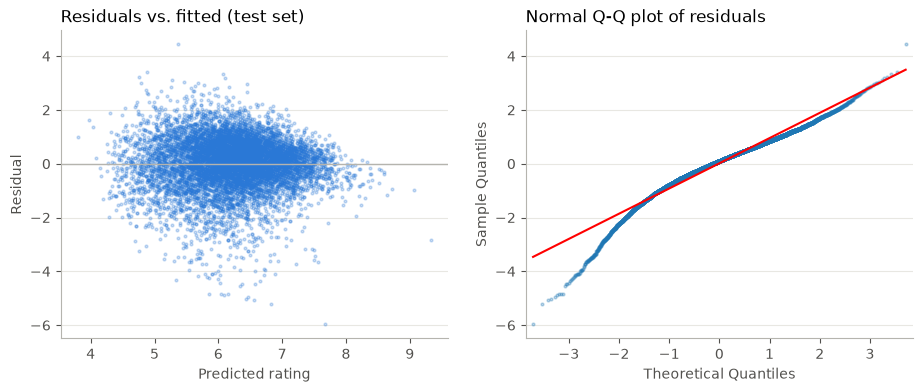

In [13]:
residuals = y_test_chosen - test_predictions

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.scatter(test_predictions, residuals, s=4, alpha=0.25, color=ERA_COLORS["Middle"])
left.axhline(0, color="#b5b4ae", linewidth=1)
left.set_title("Residuals vs. fitted (test set)")
left.set_xlabel("Predicted rating")
left.set_ylabel("Residual")
sm.qqplot(residuals, line="s", ax=right, markersize=2, alpha=0.3)
right.set_title("Normal Q-Q plot of residuals")
plt.show()

# Model checks

### Is the improvement bigger than the fold-to-fold noise?

The CV RMSE above is an average over 5 folds. If a model wins in every fold, the gain is not luck.

In [14]:
fold_scores = {}
for model_name, formula in FORMULAS.items():
    y, X = design(formula, train)
    scores = cross_validate(LinearRegression(), X, y, cv=cv_folds,
                            scoring="neg_root_mean_squared_error")
    fold_scores[model_name] = -scores["test_score"]

fold_scores = pd.DataFrame(fold_scores, index=[f"Fold {i}" for i in range(1, 6)])
fold_scores.loc["Mean"] = fold_scores.mean()
fold_scores.loc["Standard deviation"] = fold_scores.iloc[:5].std()
fold_scores.round(4)

,No era,Era,Era x features
Fold 1,0.9612,0.9405,0.9337
Fold 2,0.9605,0.9365,0.9313
Fold 3,0.9578,0.9312,0.9254
Fold 4,0.9608,0.9375,0.9325
Fold 5,0.9653,0.9478,0.9410
Mean,0.9611,0.9387,0.9328
Standard deviation,0.0027,0.0061,0.0056


### Why ridge and lasso match OLS

The penalty each one picked by cross-validation, and how many coefficients lasso set to zero.

In [15]:
y, X = design(FORMULAS["Era x features"], train)
X_scaled = StandardScaler().fit_transform(X)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 25)).fit(X_scaled, y)
lasso = LassoCV(cv=5, random_state=42).fit(X_scaled, y)

print(f"Ridge penalty (alpha): {ridge.alpha_:.2f}")
print(f"Lasso penalty (alpha): {lasso.alpha_:.5f}")
print(f"Lasso coefficients set to zero: {(lasso.coef_ == 0).sum()} of {len(lasso.coef_)}")
print(f"Training movies: {len(train):,}, inputs: {X.shape[1]}")

Ridge penalty (alpha): 17.78
Lasso penalty (alpha): 0.00039
Lasso coefficients set to zero: 0 of 47
Training movies: 38,772, inputs: 47


### OLS assumptions: equal variance and normal residuals

The Breusch-Pagan test checks whether the residuals have the same spread for every prediction. If
they don't, the usual standard errors can be off, so the era gap is re-estimated with robust (HC3)
standard errors.

In [16]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_p_value = het_breuschpagan(era_fit.resid, era_fit.model.exog)[1]
print(f"Breusch-Pagan p-value: {bp_p_value:.3g}")
print(f"Residual skew: {era_fit.resid.skew():.2f}")

robust_fit = smf.ols(FORMULAS["Era"], data=train).fit(cov_type="HC3")
pd.DataFrame({
    "Rating gap": era_fit.params[era_terms],
    "Usual 95% CI": [f"{low:.3f} to {high:.3f}" for low, high in era_fit.conf_int().loc[era_terms].values],
    "Robust 95% CI": [f"{low:.3f} to {high:.3f}" for low, high in robust_fit.conf_int().loc[era_terms].values],
})

Breusch-Pagan p-value: 3.95e-223
Residual skew: -0.83


,Rating gap,Usual 95% CI,Robust 95% CI
"C(era, Treatment('New'))[T.Old]",0.564958,0.538 to 0.592,0.541 to 0.589
"C(era, Treatment('New'))[T.Middle]",0.282370,0.256 to 0.309,0.256 to 0.308


### Do the results depend on where the eras are cut?

The same "Era" model with different cutoffs between Old, Middle, and New.

In [17]:
cutoff_results = []
for old_end, middle_end in [(1969, 1999), (1979, 1999), (1989, 2009)]:
    recut = movies.copy()
    recut["era"] = pd.cut(recut["startYear"], bins=[0, old_end, middle_end, 3000], labels=ERAS)
    recut["popularity_pct"] = recut.groupby("era", observed=True)["numVotes"].rank(pct=True)
    fit = smf.ols(FORMULAS["Era"], data=recut).fit()
    cutoff_results.append({
        "Old": f"before {old_end + 1}",
        "Middle": f"{old_end + 1}-{middle_end}",
        "New": f"{middle_end + 1}+",
        "Old gap vs. new": fit.params[era_terms[0]],
        "Middle gap vs. new": fit.params[era_terms[1]],
    })

pd.DataFrame(cutoff_results).round(3)

,Old,Middle,New,Old gap vs. new,Middle gap vs. new
0,before 1970,1970-1999,2000+,0.613,0.331
1,before 1980,1980-1999,2000+,0.568,0.281
2,before 1990,1990-2009,2010+,0.532,0.183


# Limitations

- **Survivorship.** Popularity within the era compares movies at the same rank, but the pool of old
  movies with 1,000+ votes is already made of movies people chose to watch decades later.
- **Today's raters.** IMDb ratings are mostly given by people watching now, not audiences at release.
- **"Better" means IMDb rating.** Visual quality, budget, and critic scores aren't in this version.
  Budget and other TMDB features can be added once the full TMDB pull is available.

# Findings

*To write: what Part 1 and Part 2 show about the question.*